# MEDE U12 · CP3: harta relatiilor si protocolul experimental
**Unitate:** statie × zi, Bucuresti, 2025 · **Surse:** calitateaer.ro (poluanti) + Open-Meteo (meteo)

Intrare: `data/processed/X_features.csv` si `feature_dictionary.csv` (rezultatul `02_features.ipynb`).
Iesiri: `data/processed/` (tabele) si `figures/harta_relatiilor.png`. Rulare: *Restart & Run All*.

1. **Harta relatiilor** intre cele doua surse: corelatie Spearman, informatie mutuala, CCA si graf de similaritate kNN.
2. **Protocol experimental**: PCA (baseline) vs. autoencoder, pe fiecare sursa separat si pe datele combinate, cu split spatial, 5 seed-uri si split temporal.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.cross_decomposition import CCA
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.manifold import trustworthiness
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG = ROOT / "data" / "processed", ROOT / "figures"
FIG.mkdir(exist_ok=True)
K = 6                 # dimensiunea reprezentarii (aleasa la CP2: 82% din varianta)
KNN = 10              # vecini pentru graf si trustworthiness
SEEDS = [0, 1, 2, 3, 4]
plt.rcParams.update({"figure.dpi": 130, "font.size": 8})

In [2]:
X = pd.read_csv(PROC / "X_features.csv", parse_dates=["date"])
fd = pd.read_csv(PROC / "feature_dictionary.csv")
feat_col, grp_col, tr_col = fd.columns[0], "grup", "transformare"
FEATURES = fd[feat_col].tolist()
LOG_COLS = fd.loc[fd[tr_col].str.startswith("log1p"), feat_col].tolist()
A = fd.loc[fd[grp_col].str.startswith("calitateaer"), feat_col].tolist()   # poluanti
B = fd.loc[fd[grp_col].str.startswith("Open"), feat_col].tolist()          # meteo
VIEWS = {"poluanti": A, "meteo": B, "combinat": FEATURES}
print(f"n = {len(X)}, d = {len(FEATURES)} | poluanti: {len(A)}, meteo: {len(B)}, combinat: {len(FEATURES)}")

def prep(df, cols):
    Z = df[cols].copy()
    c = [x for x in cols if x in LOG_COLS]
    Z[c] = np.log1p(Z[c])
    return Z.values

n = 1020, d = 26 | poluanti: 15, meteo: 10, combinat: 26


## 1. Harta relatiilor intre surse
Toate calculele din aceasta sectiune sunt **exploratorii** (pe toate randurile), cu exceptia corelatiilor canonice, raportate si pe statie de test.
### 1.1 Corelatie Spearman (poluanti × meteo)

In [3]:
spear = X[A + B].corr(method="spearman").loc[A, B]
spear.round(3).to_csv(PROC / "spearman_cross_source.csv")
spear.stack().abs().sort_values(ascending=False).head(5).round(2)

PM10_mean     P_sum_3d    0.53
PM10_evening  P_sum_3d    0.50
PM10_max      P_sum_3d    0.48
NO2_std       T_range     0.46
PM10_lag1     P_sum_3d    0.45
dtype: float64

### 1.2 Informatie mutuala (poluanti × meteo)
Prinde si relatii neliniare. Estimator kNN (`mutual_info_regression`), pe trasaturi transformate si standardizate; valori in nats.

In [4]:
ZA = StandardScaler().fit_transform(prep(X, A))
ZB = StandardScaler().fit_transform(prep(X, B))
mi = pd.DataFrame({a: mutual_info_regression(ZB, ZA[:, i], n_neighbors=3, random_state=0)
                   for i, a in enumerate(A)}, index=B).T
mi.round(3).to_csv(PROC / "mi_cross_source.csv")
mi.stack().sort_values(ascending=False).head(5).round(2)

PM10_lag1     P_sum_3d    0.18
PM10_morning  T_mean      0.18
NO2_std       T_range     0.17
PM10_evening  P_sum_3d    0.17
PM10_mean     W_max       0.16
dtype: float64

### 1.3 CCA intre cele doua surse (multi-view)
Directiile comune ale poluantilor si meteo. Se raporteaza corelatiile canonice pe toate randurile si pe **statia de test** (CCA potrivit pe celelalte doua statii).

In [5]:
NC = 3
cca = CCA(n_components=NC, max_iter=2000).fit(ZA, ZB)
xs, ys = cca.transform(ZA, ZB)
r_all = [np.corrcoef(xs[:, i], ys[:, i])[0, 1] for i in range(NC)]

r_test = []
for st in sorted(X["station"].unique()):
    tr, te = (X["station"] != st).values, (X["station"] == st).values
    sa, sb = StandardScaler().fit(prep(X[tr], A)), StandardScaler().fit(prep(X[tr], B))
    m = CCA(n_components=NC, max_iter=2000).fit(sa.transform(prep(X[tr], A)), sb.transform(prep(X[tr], B)))
    a_, b_ = m.transform(sa.transform(prep(X[te], A)), sb.transform(prep(X[te], B)))
    r_test.append([np.corrcoef(a_[:, i], b_[:, i])[0, 1] for i in range(NC)])
r_test = np.array(r_test)
cca_res = pd.DataFrame({"componenta": [f"CC{i+1}" for i in range(NC)], "r_toate": r_all,
                        "r_test_medie": r_test.mean(0), "r_test_std": r_test.std(0)})
cca_res.round(3).to_csv(PROC / "cca_results.csv", index=False)

# coeficienti de structura pentru prima pereche canonica
load = pd.concat([
    pd.Series([np.corrcoef(ZA[:, i], xs[:, 0])[0, 1] for i in range(len(A))], index=A),
    pd.Series([np.corrcoef(ZB[:, i], ys[:, 0])[0, 1] for i in range(len(B))], index=B)]).rename("CC1")
load.round(3).to_csv(PROC / "cca_loadings_cc1.csv")
print(cca_res.round(3).to_string(index=False))
load.reindex(load.abs().sort_values(ascending=False).index).head(6).round(2)

componenta  r_toate  r_test_medie  r_test_std
       CC1    0.723         0.647       0.057
       CC2    0.567         0.387       0.062
       CC3    0.478         0.443       0.052


T_range        -0.83
PM10_max       -0.80
PM10_mean      -0.77
PM10_morning   -0.74
NO2_max        -0.74
PM10_std       -0.70
Name: CC1, dtype: float64

### 1.4 Graf de similaritate kNN intre zile
Pentru fiecare sursa (si pentru datele combinate) se construieste graful celor 10 vecini cei mai apropiati dintre zile (fara vecinii din aceeasi zi, de la celelalte statii). Se masoara: cat de mult se suprapun grafurile celor doua surse si cat de des leaga o zi de zile din **acelasi anotimp** sau **aceeasi statie** (omofilie), fata de nivelul asteptat intamplator.

In [6]:
dates = X["date"].values
def knn_idx(Z, k=KNN, extra=5):
    # vecinii din aceeasi zi (alte statii) se exclud: B-3 si B-6 au meteo identic, deci ar fi vecini triviali
    idx = NearestNeighbors(n_neighbors=k + 1 + extra).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    return np.array([[j for j in row if dates[j] != dates[i]][:k] for i, row in enumerate(idx)])

G = {v: knn_idx(StandardScaler().fit_transform(prep(X, cols))) for v, cols in VIEWS.items()}
def overlap(g1, g2):
    return np.mean([len(set(a) & set(b)) / KNN for a, b in zip(g1, g2)])
def homophily(g, labels):
    lab = np.asarray(labels)
    return np.mean(lab[g] == lab[:, None])
def chance(labels):
    p = pd.Series(labels).value_counts(normalize=True)
    return float((p ** 2).sum())

rows = [{"graf": v, "omofilie_anotimp": homophily(g, X["anotimp"]), "omofilie_statie": homophily(g, X["station"])}
        for v, g in G.items()]
knn = pd.DataFrame(rows)
knn["asteptat_anotimp"], knn["asteptat_statie"] = chance(X["anotimp"]), chance(X["station"])
ov = pd.DataFrame({"pereche": ["poluanti-meteo", "poluanti-combinat", "meteo-combinat"],
                   "suprapunere": [overlap(G["poluanti"], G["meteo"]), overlap(G["poluanti"], G["combinat"]),
                                   overlap(G["meteo"], G["combinat"])],
                   "asteptat": KNN / (len(X) - 1)})
knn.round(3).to_csv(PROC / "knn_graph_metrics.csv", index=False)
ov.round(3).to_csv(PROC / "knn_graph_overlap.csv", index=False)
print(knn.round(3).to_string(index=False)); print(ov.round(3).to_string(index=False))

    graf  omofilie_anotimp  omofilie_statie  asteptat_anotimp  asteptat_statie
poluanti             0.350            0.525              0.25            0.333
   meteo             0.636            0.340              0.25            0.333
combinat             0.562            0.535              0.25            0.333
          pereche  suprapunere  asteptat
   poluanti-meteo        0.034      0.01
poluanti-combinat        0.295      0.01
   meteo-combinat        0.183      0.01


### 1.5 Harta relatiilor (figura)

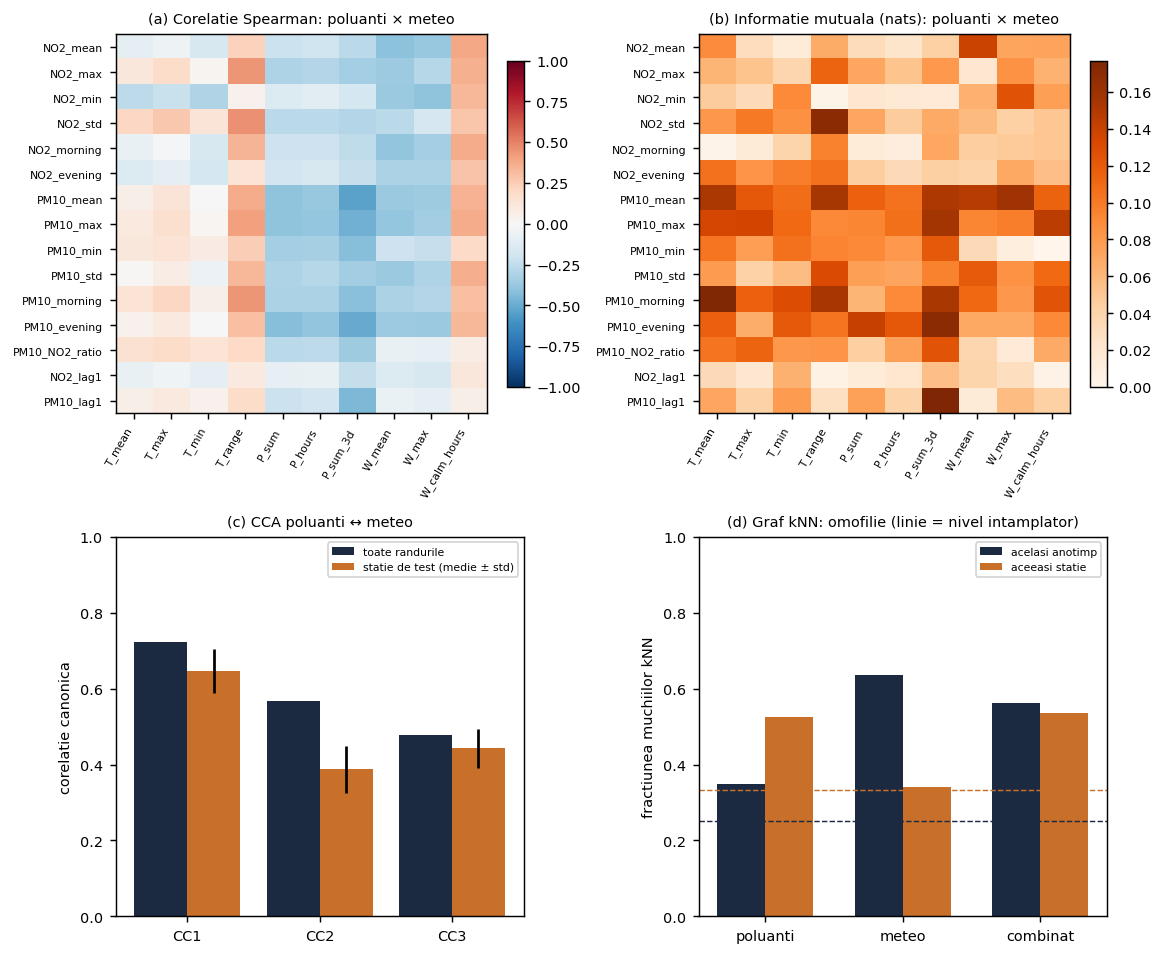

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7.4))
for ax, M_, ttl, cmap, lim in [(axes[0, 0], spear, "(a) Corelatie Spearman", "RdBu_r", (-1, 1)),
                               (axes[0, 1], mi, "(b) Informatie mutuala (nats)", "Oranges", (0, mi.values.max()))]:
    im = ax.imshow(M_.values, cmap=cmap, vmin=lim[0], vmax=lim[1], aspect="auto")
    ax.set_xticks(range(len(B))); ax.set_xticklabels(B, rotation=60, ha="right", fontsize=6)
    ax.set_yticks(range(len(A))); ax.set_yticklabels(A, fontsize=6)
    ax.set_title(ttl + ": poluanti × meteo", fontsize=8); plt.colorbar(im, ax=ax, fraction=.04)
ax = axes[1, 0]
xx = np.arange(NC)
ax.bar(xx - .2, cca_res["r_toate"], .4, color="#1B2A41", label="toate randurile")
ax.bar(xx + .2, cca_res["r_test_medie"], .4, yerr=cca_res["r_test_std"], color="#C8702A", label="statie de test (medie ± std)")
ax.set_xticks(xx); ax.set_xticklabels(cca_res["componenta"]); ax.set_ylim(0, 1)
ax.set_ylabel("corelatie canonica"); ax.set_title("(c) CCA poluanti ↔ meteo", fontsize=8); ax.legend(fontsize=6)
ax = axes[1, 1]
w = .35; xx = np.arange(len(knn))
ax.bar(xx - w / 2, knn["omofilie_anotimp"], w, color="#1B2A41", label="acelasi anotimp")
ax.bar(xx + w / 2, knn["omofilie_statie"], w, color="#C8702A", label="aceeasi statie")
ax.axhline(knn["asteptat_anotimp"][0], color="#1B2A41", ls="--", lw=.8)
ax.axhline(knn["asteptat_statie"][0], color="#C8702A", ls="--", lw=.8)
ax.set_xticks(xx); ax.set_xticklabels(knn["graf"]); ax.set_ylim(0, 1)
ax.set_ylabel("fractiunea muchiilor kNN"); ax.set_title("(d) Graf kNN: omofilie (linie = nivel intamplator)", fontsize=8)
ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig(FIG / "harta_relatiilor.png"); plt.show()

## 2. Protocol experimental
**Ce se compara:** PCA (baseline liniar) vs. **autoencoder** (MLP `16-6-16`, activare tanh, oprire timpurie) cu aceeasi dimensiune k = 6, pe trei vederi ale datelor: **poluanti** (o singura sursa), **meteo** (o singura sursa) si **combinat**. Baseline-ul pe o singura sursa este PCA pe poluanti si PCA pe meteo.

**Split:** spatial, cu o statie lasata la test (3 pliuri); scalarea (log1p + z-score) si reprezentarea se potrivesc **doar pe antrenare**. Stabilitate: 5 seed-uri (autoencoder) si split temporal (antrenare ianuarie–iunie / test iulie–decembrie si invers).

**Metrici pe datele de test:** varianta explicata (R² = 1 − SSE / SST), eroarea de reconstructie (MSE, unitati standardizate) si trustworthiness (10 vecini).

In [8]:
def fit_pca(Ztr, k, seed):
    p = PCA(n_components=k).fit(Ztr)
    return lambda Z: (p.transform(Z), p.inverse_transform(p.transform(Z)))

def fit_ae(Ztr, k, seed):
    m = MLPRegressor(hidden_layer_sizes=(16, k, 16), activation="tanh", alpha=1e-4, max_iter=2000,
                     early_stopping=True, n_iter_no_change=20, random_state=seed).fit(Ztr, Ztr)
    def f(Z):
        h = Z
        for W, b in zip(m.coefs_[:2], m.intercepts_[:2]):   # stratul ingust = codul de dimensiune k
            h = np.tanh(h @ W + b)
        return h, m.predict(Z)
    return f

METHODS = {"PCA": (fit_pca, [0]), "autoencoder": (fit_ae, SEEDS)}

def metrics(Z, E, R):
    sse, sst = ((Z - R) ** 2).sum(), ((Z - Z.mean(0)) ** 2).sum()
    return {"R2": 1 - sse / sst, "MSE": ((Z - R) ** 2).mean(), "trustworthiness": trustworthiness(Z, E, n_neighbors=KNN)}

def run_protocol(folds, split_name):
    out = []
    for fold, (tr, te) in folds.items():
        for view, cols in VIEWS.items():
            sc = StandardScaler().fit(prep(X[tr], cols))
            Ztr, Zte = sc.transform(prep(X[tr], cols)), sc.transform(prep(X[te], cols))
            for name, (fit, seeds) in METHODS.items():
                for s in seeds:
                    E, R = fit(Ztr, K, s)(Zte)
                    out.append({"split": split_name, "vedere": view, "metoda": name, "pliu": fold, "seed": s,
                                **metrics(Zte, E, R)})
    return out

spatial = {st: ((X["station"] != st).values, (X["station"] == st).values) for st in sorted(X["station"].unique())}
h1 = (X["date"].dt.month <= 6).values
temporal = {"H1->H2": (h1, ~h1), "H2->H1": (~h1, h1)}
runs = pd.DataFrame(run_protocol(spatial, "spatial") + run_protocol(temporal, "temporal"))
runs.round(4).to_csv(PROC / "pca_vs_ae_runs.csv", index=False)
print(len(runs), "rulari")

90 rulari


In [9]:
def summarize(df):
    # medie pe plieuri pentru fiecare seed -> medie ± std intre seed-uri; std intre plieuri separat
    per_seed = df.groupby(["split", "vedere", "metoda", "seed"])[["R2", "MSE", "trustworthiness"]].mean()
    g = per_seed.groupby(["split", "vedere", "metoda"])
    mean, sd_seed = g.mean(), g.std(ddof=0)
    per_fold = df.groupby(["split", "vedere", "metoda", "pliu"])[["R2", "MSE", "trustworthiness"]].mean()
    sd_fold = per_fold.groupby(["split", "vedere", "metoda"]).std(ddof=0)
    return pd.concat({"medie": mean, "std_seed": sd_seed, "std_pliu": sd_fold}, axis=1)

summ = summarize(runs)
summ.round(3).to_csv(PROC / "pca_vs_ae_summary.csv")
order = [("poluanti", "PCA"), ("poluanti", "autoencoder"), ("meteo", "PCA"), ("meteo", "autoencoder"),
         ("combinat", "PCA"), ("combinat", "autoencoder")]
sp = summ.loc["spatial"].reindex(order)
sp.round(3)

medie                        std_seed         \
                         R2    MSE trustworthiness       R2    MSE   
vedere   metoda                                                      
poluanti PCA          0.918  0.076           0.995    0.000  0.000   
         autoencoder  0.890  0.103           0.966    0.002  0.002   
meteo    PCA          0.989  0.011           1.000    0.000  0.000   
         autoencoder  0.983  0.017           0.988    0.000  0.000   
combinat PCA          0.778  0.214           0.982    0.000  0.000   
         autoencoder  0.761  0.231           0.972    0.006  0.006   

                                     std_pliu                         
                     trustworthiness       R2    MSE trustworthiness  
vedere   metoda                                                       
poluanti PCA                   0.000    0.004  0.006           0.001  
         autoencoder           0.002    0.006  0.014           0.002  
meteo    PCA                   0.000    0.000  0.000           0.000  
         autoencoder           0.001    0.000  0.000           0.000  
combinat PCA                   0.000    0.010  0.021           0.001  
         autoencoder           0.001    0.007  0.019           0.001

In [10]:
print("Stabilitate: split temporal (doar vederea combinata)")
summ.loc["temporal"].loc["combinat"].round(3)

Stabilitate: split temporal (doar vederea combinata)


medie                        std_seed                         \
                R2    MSE trustworthiness       R2    MSE trustworthiness   
metoda                                                                      
PCA          0.783  0.219           0.983    0.000  0.000           0.000   
autoencoder  0.762  0.241           0.976    0.003  0.003           0.001   

            std_pliu                         
                  R2    MSE trustworthiness  
metoda                                       
PCA            0.006  0.001           0.001  
autoencoder    0.004  0.004           0.001

## 3. Verificari

In [11]:
assert np.isfinite(runs[["R2", "MSE", "trustworthiness"]].values).all()
assert runs[runs["metoda"] == "autoencoder"]["seed"].nunique() == len(SEEDS)
assert len(runs) == (3 * 3 * (1 + len(SEEDS))) + (2 * 3 * (1 + len(SEEDS)))
print("OK")

OK
